# AQUA-STRAT — LSTM Hotspot Forecasting v5 (FULL FIX)

This version fixes the data-selection and model-input issues without changing the project into a different method.

### Included fixes
- Uses the **Global Ocean Physics Reanalysis MY** IO chunks you just downloaded.
- Automatically combines the 4 IO NetCDF chunks into one 2025 series.
- Ignores old ANFC IO files when the new MY IO files are present.
- Requires only `grid_master_full.csv` as the master grid.
- Adds the missing static drivers: wildlife exposure, habitat sensitivity, latitude and longitude.
- Adds calendar features and current magnitude.
- Uses train-only feature normalization.
- Balances regional contribution to the training loss so the much larger IO region does not dominate.
- Keeps the sequence pipeline memory-safe.
- Reports overall and per-region MAE/RMSE/R².
- Saves the model, metrics, predictions and an interactive Folium HTML map.

**Important:** this fixes the known problems, but exact R² values such as 0.90 / 0.80 / 0.70 cannot honestly be guaranteed before the model runs.

## Step 1 — Mount Drive and imports

In [6]:
from google.colab import drive
drive.mount("/content/drive")

import os
import glob
import zipfile
import shutil
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xarray as xr

BASE = "/content/drive/MyDrive/Aquastrat"
MASTER_GRID_PATH = "/content/grid_master_full.csv"
SCRATCH = "/content/aqua_strat_nc_scratch"

os.makedirs(SCRATCH, exist_ok=True)

print("BASE:", BASE)
print("Drive folder exists:", os.path.exists(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE: /content/drive/MyDrive/Aquastrat
Drive folder exists: True


## Step 2 — Upload only `grid_master_full.csv` if needed

In [5]:
if not os.path.exists(MASTER_GRID_PATH):
    from google.colab import files
    print("Upload ONLY grid_master_full.csv")
    uploaded = files.upload()

    csv_names = [n for n in uploaded if n.lower().endswith(".csv")]
    if len(csv_names) != 1:
        raise FileNotFoundError("Please upload exactly one CSV file.")

    os.replace(csv_names[0], MASTER_GRID_PATH)

master = pd.read_csv(MASTER_GRID_PATH)
master["region"] = master["region"].astype(str).str.upper()

required_cols = {
    "grid_id", "region", "lat_center", "lon_center",
    "wildlife_exposure", "habitat_sensitivity"
}
missing = required_cols - set(master.columns)
if missing:
    raise ValueError(f"grid_master_full.csv is missing: {sorted(missing)}")

print("Master grid:", master.shape)
print(master["region"].value_counts())

Upload ONLY grid_master_full.csv


Saving grid_master_full.csv to grid_master_full.csv
Master grid: (15976, 18)
region
IO     10355
BOB     3349
AS      2272
Name: count, dtype: int64


## Step 3 — Discover NetCDF data

The new IO files are selected from the **MY reanalysis** product. Old ANFC IO files are deliberately ignored when the new MY files are found.

In [7]:
DYNAMIC_VARS = ["thetao", "so", "uo", "vo", "zos"]
REGIONS = ["AS", "BOB", "IO"]

def all_files(base):
    out = []
    for root, dirs, files in os.walk(base):
        for f in files:
            out.append(os.path.join(root, f))
    return out

all_paths = all_files(BASE)
direct_nc = [p for p in all_paths if p.lower().endswith(".nc")]
zip_paths = [p for p in all_paths if p.lower().endswith(".zip")]

print("Direct NC files:", len(direct_nc))
print("ZIP files:", len(zip_paths))

for p in direct_nc:
    print("NC:", p)
for p in zip_paths:
    print("ZIP:", p)

Direct NC files: 0
ZIP files: 1
ZIP: /content/drive/MyDrive/Aquastrat/Copernicus ocean currents dataset.zip


In [8]:
def extract_nc_from_zip(zip_path, out_root):
    out_dir = os.path.join(out_root, os.path.splitext(os.path.basename(zip_path))[0])
    os.makedirs(out_dir, exist_ok=True)
    extracted = []

    try:
        with zipfile.ZipFile(zip_path, "r") as zf:
            for member in zf.namelist():
                if not member.lower().endswith(".nc"):
                    continue

                safe = os.path.normpath(member)
                if safe.startswith("..") or os.path.isabs(safe):
                    continue

                target = os.path.join(out_dir, safe)
                os.makedirs(os.path.dirname(target), exist_ok=True)

                if not os.path.exists(target):
                    with zf.open(member) as src, open(target, "wb") as dst:
                        shutil.copyfileobj(src, dst, length=1024 * 1024)

                extracted.append(target)
    except Exception as e:
        print("[WARN] ZIP:", zip_path, "|", e)

    return sorted(set(extracted))

zip_nc = []
for zp in zip_paths:
    low = os.path.basename(zp).lower()
    if ".safe" in low or "sentinel" in low:
        print("Skipping optical/Sentinel archive:", zp)
        continue
    zip_nc.extend(extract_nc_from_zip(zp, SCRATCH))

all_nc = sorted(set(direct_nc + zip_nc))
print("Total NC candidates:", len(all_nc))
for p in all_nc:
    print(" -", p)

Total NC candidates: 6
 - /content/aqua_strat_nc_scratch/Copernicus ocean currents dataset/Copernicus ocean currents dataset/Arabian region/cmems_mod_glo_phy_my_0.083deg_P1D-m_1786023963926.nc
 - /content/aqua_strat_nc_scratch/Copernicus ocean currents dataset/Copernicus ocean currents dataset/Bay of bengal/cmems_mod_glo_phy_my_0.083deg_P1D-m_1786020800727.nc
 - /content/aqua_strat_nc_scratch/Copernicus ocean currents dataset/Copernicus ocean currents dataset/New Indian ocean/cmems_mod_glo_phy_my_0.083deg_P1D-m_1786866378009.nc
 - /content/aqua_strat_nc_scratch/Copernicus ocean currents dataset/Copernicus ocean currents dataset/New Indian ocean/cmems_mod_glo_phy_my_0.083deg_P1D-m_1786866665639.nc
 - /content/aqua_strat_nc_scratch/Copernicus ocean currents dataset/Copernicus ocean currents dataset/New Indian ocean/cmems_mod_glo_phy_my_0.083deg_P1D-m_1786866871505.nc
 - /content/aqua_strat_nc_scratch/Copernicus ocean currents dataset/Copernicus ocean currents dataset/New Indian ocean/cme

In [9]:
def nc_info(path):
    try:
        ds = xr.open_dataset(path, decode_times=True)

        lat_name = "latitude" if "latitude" in ds.coords else ("lat" if "lat" in ds.coords else None)
        lon_name = "longitude" if "longitude" in ds.coords else ("lon" if "lon" in ds.coords else None)

        if lat_name and lon_name:
            lat_min = float(ds[lat_name].min())
            lat_max = float(ds[lat_name].max())
            lon_min = float(ds[lon_name].min())
            lon_max = float(ds[lon_name].max())
        else:
            lat_min = lat_max = lon_min = lon_max = np.nan

        times = pd.to_datetime(ds["time"].values) if "time" in ds.coords else pd.DatetimeIndex([])
        info = {
            "vars": set(ds.data_vars),
            "lat_min": lat_min,
            "lat_max": lat_max,
            "lon_min": lon_min,
            "lon_max": lon_max,
            "time_min": str(times.min())[:10] if len(times) else "?",
            "time_max": str(times.max())[:10] if len(times) else "?",
            "ntime": len(times),
        }
        ds.close()
        return info
    except Exception as e:
        print("[WARN]", os.path.basename(path), e)
        return None

infos = {}
for p in all_nc:
    x = nc_info(p)
    if x is not None:
        infos[p] = x

# The four newly downloaded IO files.
io_my = [
    p for p, info in infos.items()
    if "_my_0.083deg_p1d" in os.path.basename(p).lower()
    and set(DYNAMIC_VARS).issubset(info["vars"])
    and (
        "indian ocean" in p.lower()
        or "new indian ocean" in p.lower()
        or "indian_ocean" in p.lower()
        or "indianocean" in p.lower()
    )
]

# Fallback if the folder has a different name: identify a full IO MY footprint.
if not io_my:
    io_my = [
        p for p, info in infos.items()
        if "_my_0.083deg_p1d" in os.path.basename(p).lower()
        and set(DYNAMIC_VARS).issubset(info["vars"])
        and info["lat_min"] <= -19
        and info["lat_max"] >= 24
        and info["lon_min"] <= 41
        and info["lon_max"] >= 99
    ]

if not io_my:
    raise FileNotFoundError(
        "The new IO MY files were not found. Put the four downloaded .nc files "
        "inside AquaStrat/New Indian Ocean (or a subfolder under AquaStrat)."
    )

def overlaps_region(path, region):
    info = infos[path]
    g = master[master["region"] == region]
    if g.empty:
        return False
    return (
        info["lat_min"] <= g["lat_center"].max()
        and info["lat_max"] >= g["lat_center"].min()
        and info["lon_min"] <= g["lon_center"].max()
        and info["lon_max"] >= g["lon_center"].min()
    )

as_candidates = []
bob_candidates = []

for p, info in infos.items():
    low = p.lower()
    if p in io_my:
        continue
    if "indian ocean" in low or "new indian ocean" in low:
        continue

    if "arabian" in low or os.path.basename(p).lower() == "ocean_physics.nc":
        as_candidates.append(p)
    elif "bengal" in low or "bob" in low:
        bob_candidates.append(p)

if not as_candidates:
    as_candidates = [p for p in infos if p not in io_my and overlaps_region(p, "AS")]

if not bob_candidates:
    bob_candidates = [p for p in infos if p not in io_my and overlaps_region(p, "BOB")]

as_candidates = sorted(set(as_candidates))
bob_candidates = sorted(set(bob_candidates))
io_my = sorted(set(io_my))

print("\n=== SELECTED ===")
print("AS:")
for p in as_candidates:
    print(" ", os.path.basename(p), infos[p]["vars"], infos[p]["time_min"], "to", infos[p]["time_max"])
print("BOB:")
for p in bob_candidates:
    print(" ", os.path.basename(p), infos[p]["vars"], infos[p]["time_min"], "to", infos[p]["time_max"])
print("IO MY:")
for p in io_my:
    print(" ", os.path.basename(p), infos[p]["vars"], infos[p]["time_min"], "to", infos[p]["time_max"])


=== SELECTED ===
AS:
  cmems_mod_glo_phy_my_0.083deg_P1D-m_1786023963926.nc {'uo', 'vo', 'zos', 'thetao', 'so'} 2025-01-01 to 2026-01-01
BOB:
  cmems_mod_glo_phy_my_0.083deg_P1D-m_1786020800727.nc {'uo', 'vo', 'zos', 'thetao', 'so'} 2025-01-01 to 2026-01-01
IO MY:
  cmems_mod_glo_phy_my_0.083deg_P1D-m_1786866378009.nc {'uo', 'vo', 'zos', 'thetao', 'so'} 2025-01-01 to 2025-04-01
  cmems_mod_glo_phy_my_0.083deg_P1D-m_1786866665639.nc {'uo', 'vo', 'zos', 'thetao', 'so'} 2025-04-01 to 2025-07-01
  cmems_mod_glo_phy_my_0.083deg_P1D-m_1786866871505.nc {'uo', 'vo', 'zos', 'thetao', 'so'} 2025-07-01 to 2025-10-01
  cmems_mod_glo_phy_my_0.083deg_P1D-m_1786867058360.nc {'uo', 'vo', 'zos', 'thetao', 'so'} 2025-10-01 to 2026-01-01


## Step 4 — Open regional datasets safely

In [10]:
def open_nc_group(paths, label):
    paths = sorted(set(paths))
    if not paths:
        return None

    print(f"[{label}] opening {len(paths)} file(s)")

    if len(paths) == 1:
        ds = xr.open_dataset(paths[0], chunks={})
    else:
        try:
            ds = xr.open_mfdataset(
                paths,
                combine="by_coords",
                chunks={},
                parallel=False,
                compat="override",
                coords="minimal",
                data_vars="minimal",
                join="outer",
            )
        except Exception as e:
            print(f"[{label}] open_mfdataset failed:", e)
            parts = [xr.open_dataset(p, chunks={}) for p in paths]
            ds = xr.concat(parts, dim="time").sortby("time")

    if "depth" in ds.dims and ds.sizes["depth"] == 1:
        ds = ds.squeeze("depth", drop=True)

    keep = [v for v in DYNAMIC_VARS if v in ds.data_vars]
    ds = ds[keep]

    if "time" in ds.coords:
        t = pd.to_datetime(ds.time.values)
        _, idx = np.unique(t, return_index=True)
        if len(idx) != len(t):
            ds = ds.isel(time=np.sort(idx))
        ds = ds.sortby("time")

    print(f"[{label}] dims:", dict(ds.sizes))
    print(f"[{label}] vars:", list(ds.data_vars))

    if "time" in ds.coords:
        t = pd.to_datetime(ds.time.values)
        print(f"[{label}] {str(t.min())[:10]} -> {str(t.max())[:10]} ({len(t)} days)")

    return ds

datasets = {
    "AS": open_nc_group(as_candidates, "AS"),
    "BOB": open_nc_group(bob_candidates, "BOB"),
    "IO": open_nc_group(io_my, "IO-MY"),
}

[AS] opening 1 file(s)
[AS] dims: {'time': 366, 'latitude': 175, 'longitude': 144}
[AS] vars: ['thetao', 'so', 'uo', 'vo', 'zos']
[AS] 2025-01-01 -> 2026-01-01 (366 days)
[BOB] opening 1 file(s)
[BOB] dims: {'time': 366, 'latitude': 175, 'longitude': 180}
[BOB] vars: ['thetao', 'so', 'uo', 'vo', 'zos']
[BOB] 2025-01-01 -> 2026-01-01 (366 days)
[IO-MY] opening 4 file(s)
[IO-MY] dims: {'time': 366, 'latitude': 541, 'longitude': 720}
[IO-MY] vars: ['thetao', 'so', 'uo', 'vo', 'zos']
[IO-MY] 2025-01-01 -> 2026-01-01 (366 days)


## Step 5 — Build real regional series and the existing density proxy

In [11]:
def coord_name(ds, names):
    for n in names:
        if n in ds.coords:
            return n
    return None

def fill_nan_rows(arr):
    out = np.asarray(arr, dtype=np.float32)
    for i in range(out.shape[0]):
        s = pd.Series(out[i])
        out[i] = s.interpolate(limit_direction="both").to_numpy(dtype=np.float32)
    return out

def select_grid_cells(grid, ds):
    lat_name = coord_name(ds, ["latitude", "lat"])
    lon_name = coord_name(ds, ["longitude", "lon"])

    if lat_name is None or lon_name is None:
        raise ValueError(f"Cannot find lat/lon in {list(ds.coords)}")

    lats = np.asarray(ds[lat_name].values, dtype=float)
    lons = np.asarray(ds[lon_name].values, dtype=float)

    lat_step = float(np.median(np.abs(np.diff(np.unique(lats))))) if len(lats) > 1 else 0.1
    lon_step = float(np.median(np.abs(np.diff(np.unique(lons))))) if len(lons) > 1 else 0.1

    lat_min, lat_max = lats.min() - lat_step/2, lats.max() + lat_step/2
    lon_min, lon_max = lons.min() - lon_step/2, lons.max() + lon_step/2

    keep = (
        grid["lat_center"].between(lat_min, lat_max)
        & grid["lon_center"].between(lon_min, lon_max)
        & (~grid["is_land"].astype(bool))
    )

    g = grid.loc[keep].reset_index(drop=True)
    if g.empty:
        raise ValueError("No master-grid cells are covered by the real dataset.")
    return g, lat_name, lon_name

def build_region(region, ds):
    grid = master[master["region"] == region].copy().reset_index(drop=True)
    grid, lat_name, lon_name = select_grid_cells(grid, ds)

    lat_da = xr.DataArray(grid["lat_center"].to_numpy(), dims="cell")
    lon_da = xr.DataArray(grid["lon_center"].to_numpy(), dims="cell")

    selected = ds.sel(
        {lat_name: lat_da, lon_name: lon_da},
        method="nearest",
    )

    series = {}
    for v in DYNAMIC_VARS:
        if v in selected.data_vars:
            series[v] = fill_nan_rows(np.asarray(selected[v].values).T)

    if not {"uo", "vo"}.issubset(series):
        raise ValueError(f"{region}: both uo and vo are required.")

    valid = np.ones(len(grid), dtype=bool)
    for arr in series.values():
        valid &= ~np.isnan(arr).any(axis=1)

    grid = grid.loc[valid].reset_index(drop=True)
    for v in series:
        series[v] = series[v][valid]

    n_cells, n_days = series["uo"].shape
    dates = pd.to_datetime(ds.time.values)
    doy = dates.dayofyear.to_numpy(dtype=np.float32)

    wildlife = grid["wildlife_exposure"].to_numpy(dtype=np.float32)
    habitat = grid["habitat_sensitivity"].to_numpy(dtype=np.float32)
    coastal = (0.5 * wildlife + 0.5 * habitat).reshape(-1, 1)

    monsoon = np.exp(
        -((doy - 200.0) ** 2) / (2.0 * 55.0 ** 2)
    ).reshape(1, -1)

    current_mag = np.sqrt(series["uo"]**2 + series["vo"]**2)
    cmin, cmax = current_mag.min(), current_mag.max()
    current_norm = (current_mag - cmin) / (cmax - cmin + 1e-9)

    base = (
        0.15
        + 0.5 * coastal
        * (1.0 + 1.2 * monsoon)
        * (1.0 + 0.4 * current_norm)
    )

    rng = np.random.default_rng(42 + {"AS": 1, "BOB": 2, "IO": 3}[region])
    noise = rng.normal(0, 0.05, size=(n_cells, n_days)).astype(np.float32)
    noise = (
        pd.DataFrame(noise.T)
        .rolling(5, min_periods=1, center=True)
        .mean()
        .to_numpy()
        .T
        .astype(np.float32)
    )

    density = np.clip(base + noise, 0, None)
    density = (
        (density - density.min())
        / (density.max() - density.min() + 1e-9)
    ).astype(np.float32)

    series["density"] = density

    return {
        "grid": grid,
        "series": series,
        "n_cells": n_cells,
        "n_days": n_days,
        "day_of_year": doy,
    }

region_data = {}
for r in REGIONS:
    if datasets[r] is None:
        raise RuntimeError(f"{r} has no real ocean-physics dataset.")
    region_data[r] = build_region(r, datasets[r])
    d = region_data[r]
    print(f"{r}: REAL DAILY | cells={d['n_cells']} | days={d['n_days']} | vars={list(d['series'])}")

AS: REAL DAILY | cells=1644 | days=366 | vars=['thetao', 'so', 'uo', 'vo', 'zos', 'density']
BOB: REAL DAILY | cells=2855 | days=366 | vars=['thetao', 'so', 'uo', 'vo', 'zos', 'density']
IO: REAL DAILY | cells=10278 | days=366 | vars=['thetao', 'so', 'uo', 'vo', 'zos', 'density']


## Step 6 — Feature engineering + train-only normalization

In [12]:
WINDOW = 14
HORIZON = 1

BASE_FEATURES = [
    "thetao", "so", "uo", "vo", "zos",
    "wildlife_exposure", "habitat_sensitivity",
    "lat_center", "lon_center",
    "sin_doy", "cos_doy", "current_mag"
]

STATIC_MAP = {
    "thetao": "sst",
    "so": "salinity",
    "uo": "current_u",
    "vo": "current_v",
    "zos": "ssh",
}

normalized_features = {}

for region in REGIONS:
    d = region_data[region]
    g = d["grid"]
    t = d["n_days"]
    n = d["n_cells"]

    feats = np.zeros((n, t, len(BASE_FEATURES)), dtype=np.float32)
    masks = np.ones((n, t, len(DYNAMIC_VARS)), dtype=np.float32)

    for j, v in enumerate(DYNAMIC_VARS):
        if v in d["series"]:
            feats[:, :, j] = d["series"][v]
        else:
            col = STATIC_MAP[v]
            vals = np.nan_to_num(
                g[col].to_numpy(dtype=np.float32),
                nan=0.0
            )
            feats[:, :, j] = vals[:, None]
            masks[:, :, j] = 0.0

    wildlife = g["wildlife_exposure"].to_numpy(dtype=np.float32)
    habitat = g["habitat_sensitivity"].to_numpy(dtype=np.float32)
    lat = g["lat_center"].to_numpy(dtype=np.float32)
    lon = g["lon_center"].to_numpy(dtype=np.float32)

    doy = d["day_of_year"]
    sin_doy = np.sin(2*np.pi*doy/365.25).astype(np.float32)
    cos_doy = np.cos(2*np.pi*doy/365.25).astype(np.float32)

    u = feats[:, :, 2]
    v = feats[:, :, 3]
    current_mag = np.sqrt(u*u + v*v).astype(np.float32)

    feats[:, :, 5] = wildlife[:, None]
    feats[:, :, 6] = habitat[:, None]
    feats[:, :, 7] = lat[:, None]
    feats[:, :, 8] = lon[:, None]
    feats[:, :, 9] = sin_doy[None, :]
    feats[:, :, 10] = cos_doy[None, :]
    feats[:, :, 11] = current_mag

    train_end = int(t * 0.70)

    # Normalize using TRAIN ONLY.
    for j in range(feats.shape[-1]):
        mu = np.nanmean(feats[:, :train_end, j])
        sd = np.nanstd(feats[:, :train_end, j])
        feats[:, :, j] = (feats[:, :, j] - mu) / (sd + 1e-8)

    normalized_features[region] = np.concatenate(
        [feats.astype(np.float32), masks.astype(np.float32)],
        axis=-1
    )

FEATURE_COUNT = normalized_features["AS"].shape[-1]
print("Sequence features:", FEATURE_COUNT)
print("Base:", BASE_FEATURES)
print("Plus availability masks for:", DYNAMIC_VARS)

Sequence features: 17
Base: ['thetao', 'so', 'uo', 'vo', 'zos', 'wildlife_exposure', 'habitat_sensitivity', 'lat_center', 'lon_center', 'sin_doy', 'cos_doy', 'current_mag']
Plus availability masks for: ['thetao', 'so', 'uo', 'vo', 'zos']


## Step 7 — Time split + memory-safe `tf.data`

In [13]:
import tensorflow as tf
tf.random.set_seed(42)
np.random.seed(42)

REGION_LIST = REGIONS
n_regions = len(REGION_LIST)

region_onehots = {}
for i, r in enumerate(REGION_LIST):
    z = np.zeros(n_regions, dtype=np.float32)
    z[i] = 1.0
    region_onehots[r] = z

def split_target_bounds(n_days, split):
    train_cut = int(n_days * 0.70)
    val_cut = int(n_days * 0.85)
    if split == "train":
        return 0, train_cut
    if split == "val":
        return train_cut, val_cut
    if split == "test":
        return val_cut, n_days
    raise ValueError(split)

def region_sample_count(region, split):
    n_days = region_data[region]["n_days"]
    n_windows = max(0, n_days - WINDOW - HORIZON + 1)
    target_offset = WINDOW + HORIZON - 1
    start_day, end_day = split_target_bounds(n_days, split)
    t_start = max(0, start_day - target_offset)
    t_end = min(n_windows, end_day - target_offset)
    return region_data[region]["n_cells"] * max(0, t_end - t_start)

def total_sample_count(split):
    return sum(region_sample_count(r, split) for r in REGION_LIST)

TRAIN_SAMPLES = total_sample_count("train")
VAL_SAMPLES = total_sample_count("val")
TEST_SAMPLES = total_sample_count("test")

mean_region_train = np.mean(
    [region_sample_count(r, "train") for r in REGION_LIST]
)
region_weights = {
    r: float(mean_region_train / max(1, region_sample_count(r, "train")))
    for r in REGION_LIST
}

print(f"Train={TRAIN_SAMPLES:,} | Val={VAL_SAMPLES:,} | Test={TEST_SAMPLES:,}")
print("Region training weights:", region_weights)

Train=3,576,034 | Val=812,735 | Test=812,735
Region training weights: {'AS': 2.996147607461476, 'BOB': 1.7252772913018095, 'IO': 0.47924369202828043}


In [14]:
def batch_generator(split, batch_size=256):
    for region in REGION_LIST:
        d = region_data[region]
        feats = normalized_features[region]
        density = d["series"]["density"].astype(np.float32)

        n_cells, n_days = d["n_cells"], d["n_days"]
        n_windows = max(0, n_days - WINDOW - HORIZON + 1)
        target_offset = WINDOW + HORIZON - 1

        start_day, end_day = split_target_bounds(n_days, split)
        t_start = max(0, start_day - target_offset)
        t_end = min(n_windows, end_day - target_offset)

        if t_end <= t_start:
            continue

        region_block = np.tile(
            region_onehots[region][None, :],
            (WINDOW, 1)
        ).astype(np.float32)

        weight = np.float32(region_weights[region] if split == "train" else 1.0)

        for c in range(n_cells):
            windows = np.lib.stride_tricks.sliding_window_view(
                feats[c], WINDOW, axis=0
            )
            windows = np.transpose(windows, (0, 2, 1))
            windows = windows[t_start:t_end]

            targets = density[c, (t_start + target_offset):(t_end + target_offset)]

            for start in range(0, len(windows), batch_size):
                wb = np.asarray(windows[start:start+batch_size], dtype=np.float32)
                yb = np.asarray(targets[start:start+batch_size], dtype=np.float32)

                rb = np.broadcast_to(
                    region_block[None, :, :],
                    (len(wb), WINDOW, n_regions)
                )

                xb = np.concatenate([wb, rb], axis=-1).astype(np.float32, copy=False)
                sw = np.full(len(yb), weight, dtype=np.float32)

                yield xb, yb, sw

def make_dataset(split, batch_size=256):
    return tf.data.Dataset.from_generator(
        lambda: batch_generator(split, batch_size),
        output_signature=(
            tf.TensorSpec((None, WINDOW, FEATURE_COUNT + n_regions), tf.float32),
            tf.TensorSpec((None,), tf.float32),
            tf.TensorSpec((None,), tf.float32),
        )
    ).prefetch(tf.data.AUTOTUNE)

BATCH_SIZE = 256
train_ds = make_dataset("train", BATCH_SIZE)
val_ds = make_dataset("val", BATCH_SIZE)
test_ds = make_dataset("test", BATCH_SIZE)

N_FEATURES_TOTAL = FEATURE_COUNT + n_regions
TRAIN_STEPS = max(1, int(np.ceil(TRAIN_SAMPLES / BATCH_SIZE)))
VAL_STEPS = max(1, int(np.ceil(VAL_SAMPLES / BATCH_SIZE)))
TEST_STEPS = max(1, int(np.ceil(TEST_SAMPLES / BATCH_SIZE)))

print("LSTM input:", (WINDOW, N_FEATURES_TOTAL))
print("Steps:", TRAIN_STEPS, VAL_STEPS, TEST_STEPS)
print("No giant X_all tensor is created.")

LSTM input: (14, 20)
Steps: 13969 3175 3175
No giant X_all tensor is created.


## Step 8 — Train the corrected shared LSTM

In [15]:
from tensorflow.keras import layers, models, callbacks

model = models.Sequential([
    layers.Input(shape=(WINDOW, N_FEATURES_TOTAL)),
    layers.LSTM(96, return_sequences=True),
    layers.LayerNormalization(),
    layers.Dropout(0.15),
    layers.LSTM(48),
    layers.Dropout(0.15),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-4,
        clipnorm=1.0
    ),
    loss=tf.keras.losses.Huber(delta=0.05),
    metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")],
)

model.summary()

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1,
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=35,
    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 14, 96)         │        44,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 14, 96)         │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 96)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 48)             │        27,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,073 (293.25 KB)

 Trainable params: 75,073 (293.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
13969/13969 ━━━━━━━━━━━━━━━━━━━━ 169s 12ms/step - loss: 5.9917e-04 - mae: 0.0202 - val_loss: 0.0013 - val_mae: 0.0445 - learning_rate: 5.0000e-04
Epoch 2/35
13969/13969 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - loss: 8.0053e-05 - mae: 0.0146 - val_loss: 0.0013 - val_mae: 0.0452 - learning_rate: 5.0000e-04
Epoch 3/35
13969/13969 ━━━━━━━━━━━━━━━━━━━━ 161s 12ms/step - loss: 3.6342e-04 - mae: 0.0177 - val_loss: 0.0012 - val_mae: 0.0422 - learning_rate: 5.0000e-04
Epoch 4/35
13969/13969 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - loss: 7.6908e-05 - mae: 0.0143 - val_loss: 0.0012 - val_mae: 0.0427 - learning_rate: 5.0000e-04
Epoch 5/35
13969/13969 ━━━━━━━━━━━━━━━━━━━━ 160s 11ms/step - loss: 3.2983e-04 - mae: 0.0172 - val_loss: 0.0011 - val_mae: 0.0410 - learning_rate: 5.0000e-04
Epoch 6/35
  806/13969 ━━━━━━━━━━━━━━━━━━━━ 2:28 11ms/step - loss: 7.5329e-05 - mae: 0.0142
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
13969/13969 ━━━━━━━━━━━━━━━━━━━━ 22s 2ms/step - los

## Step 9 — Evaluate overall + per region

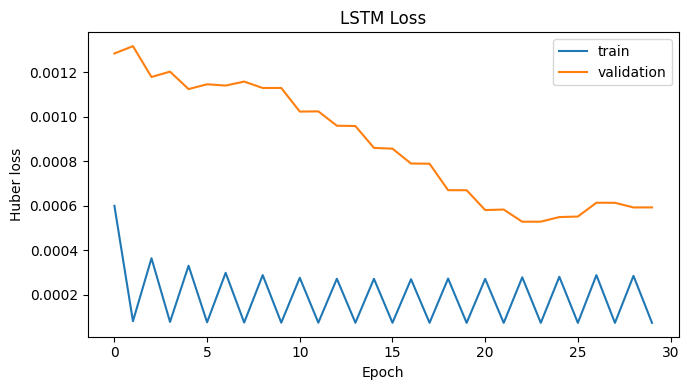

=== PER REGION ===


,Region,MAE,RMSE,R2,Test samples
0,AS,0.027362,0.032591,0.731661,90420
1,BOB,0.031304,0.043391,0.713545,157025
2,IO,0.016530,0.020547,0.480829,565290


=== OVERALL POOLED ===
MAE  = 0.0206
RMSE = 0.0278
R²   = 0.7441


In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Huber loss")
plt.legend()
plt.tight_layout()
plt.show()

def metrics_from_arrays(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    mae = np.mean(np.abs(y_pred - y_true))
    rmse = np.sqrt(np.mean((y_pred - y_true)**2))
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - y_true.mean())**2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return mae, rmse, r2

def evaluate_region(region):
    d = region_data[region]
    feats = normalized_features[region]
    density = d["series"]["density"].astype(np.float32)

    n_cells, n_days = d["n_cells"], d["n_days"]
    n_windows = max(0, n_days - WINDOW - HORIZON + 1)
    target_offset = WINDOW + HORIZON - 1

    start_day, end_day = split_target_bounds(n_days, "test")
    t_start = max(0, start_day - target_offset)
    t_end = min(n_windows, end_day - target_offset)

    region_block = np.tile(
        region_onehots[region][None, :],
        (WINDOW, 1)
    ).astype(np.float32)

    yt, yp = [], []

    for c in range(n_cells):
        windows = np.lib.stride_tricks.sliding_window_view(
            feats[c], WINDOW, axis=0
        )
        windows = np.transpose(windows, (0, 2, 1))[t_start:t_end]
        targets = density[c, (t_start + target_offset):(t_end + target_offset)]

        for start in range(0, len(windows), BATCH_SIZE):
            wb = np.asarray(windows[start:start+BATCH_SIZE], dtype=np.float32)
            yb = np.asarray(targets[start:start+BATCH_SIZE], dtype=np.float32)

            rb = np.broadcast_to(
                region_block[None, :, :],
                (len(wb), WINDOW, n_regions)
            )
            xb = np.concatenate([wb, rb], axis=-1).astype(np.float32, copy=False)

            pred = model(xb, training=False).numpy().reshape(-1)
            yt.append(yb)
            yp.append(pred)

    yt = np.concatenate(yt)
    yp = np.concatenate(yp)
    return metrics_from_arrays(yt, yp), yt, yp

rows = []
all_true = []
all_pred = []

for region in REGION_LIST:
    (mae, rmse, r2), yt, yp = evaluate_region(region)
    rows.append({
        "Region": region,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Test samples": len(yt),
    })
    all_true.append(yt)
    all_pred.append(yp)

metrics_df = pd.DataFrame(rows)

all_true = np.concatenate(all_true)
all_pred = np.concatenate(all_pred)
overall_mae, overall_rmse, overall_r2 = metrics_from_arrays(all_true, all_pred)

print("=== PER REGION ===")
display(metrics_df)

print("=== OVERALL POOLED ===")
print(f"MAE  = {overall_mae:.4f}")
print(f"RMSE = {overall_rmse:.4f}")
print(f"R²   = {overall_r2:.4f}")

## Step 10 — Predict next-day hotspots

In [17]:
all_next_day_frames = []

for region in REGION_LIST:
    d = region_data[region]
    feats = normalized_features[region]
    last_window = feats[:, -WINDOW:, :]

    region_block = np.tile(
        region_onehots[region][None, :],
        (WINDOW, 1)
    ).astype(np.float32)

    preds = []

    for start in range(0, len(last_window), BATCH_SIZE):
        wb = np.asarray(last_window[start:start+BATCH_SIZE], dtype=np.float32)
        rb = np.broadcast_to(
            region_block[None, :, :],
            (len(wb), WINDOW, n_regions)
        )
        xb = np.concatenate([wb, rb], axis=-1).astype(np.float32, copy=False)
        preds.append(model(xb, training=False).numpy().reshape(-1))

    pred = np.concatenate(preds)

    out = d["grid"][["grid_id", "lat_center", "lon_center"]].copy()
    out["region"] = region
    out["predicted_density"] = pred
    all_next_day_frames.append(out)

hotspot_df = pd.concat(all_next_day_frames, ignore_index=True)

q1, q2 = hotspot_df["predicted_density"].quantile([1/3, 2/3])

hotspot_df["hotspot_tier"] = np.select(
    [
        hotspot_df["predicted_density"] <= q1,
        hotspot_df["predicted_density"] <= q2,
    ],
    ["Low", "Medium"],
    default="High"
)

print(hotspot_df.groupby(["region", "hotspot_tier"]).size())

region  hotspot_tier
AS      High            1644
BOB     High            2855
IO      High             427
        Low             4926
        Medium          4925
dtype: int64


## Step 11 — Interactive Folium map + save as HTML

In [18]:
import folium
from folium import Element

tier_colors = {
    "Low": "#457b9d",
    "Medium": "#f4a261",
    "High": "#e63946",
}

m = folium.Map(
    location=[
        float(hotspot_df["lat_center"].mean()),
        float(hotspot_df["lon_center"].mean())
    ],
    zoom_start=4,
    tiles="CartoDB positron",
)

for _, row in hotspot_df.iterrows():
    folium.CircleMarker(
        location=[row["lat_center"], row["lon_center"]],
        radius=3,
        color=tier_colors[row["hotspot_tier"]],
        fill=True,
        fill_color=tier_colors[row["hotspot_tier"]],
        fill_opacity=0.7,
        popup=(
            f"{row['grid_id']} ({row['region']}) | "
            f"density={row['predicted_density']:.3f} | "
            f"{row['hotspot_tier']}"
        ),
    ).add_to(m)

legend_html = '''
<div style="position: fixed; bottom: 30px; left: 30px; z-index:9999;
background:white; padding:10px; border:1px solid #999;
border-radius:6px; font-size:13px;">
<b>AQUA-STRAT Predicted Hotspot Tier</b><br>
<span style="color:#457b9d;">&#9679;</span> Low<br>
<span style="color:#f4a261;">&#9679;</span> Medium<br>
<span style="color:#e63946;">&#9679;</span> High
</div>
'''

m.get_root().html.add_child(Element(legend_html))

MAP_FILE = "/content/AQUA_STRAT_Hotspot_Map.html"
m.save(MAP_FILE)

print("Interactive map saved:", MAP_FILE)
m

Interactive map saved: /content/AQUA_STRAT_Hotspot_Map.html


In [19]:
# Download the interactive HTML map
from google.colab import files
files.download(MAP_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 12 — Save model, metrics, predictions and map to Drive

In [20]:
OUT_DIR = f"{BASE}/lstm_v5_final"
os.makedirs(OUT_DIR, exist_ok=True)

model_path = f"{OUT_DIR}/aqua_strat_lstm_v5.keras"
metrics_path = f"{OUT_DIR}/lstm_test_metrics_v5.csv"
pred_path = f"{OUT_DIR}/predicted_hotspots_v5.csv"
map_drive_path = f"{OUT_DIR}/AQUA_STRAT_Hotspot_Map.html"

model.save(model_path)
metrics_df.to_csv(metrics_path, index=False)
hotspot_df.to_csv(pred_path, index=False)
shutil.copy2(MAP_FILE, map_drive_path)

print("Saved:")
print(model_path)
print(metrics_path)
print(pred_path)
print(map_drive_path)

Saved:
/content/drive/MyDrive/Aquastrat/lstm_v5_final/aqua_strat_lstm_v5.keras
/content/drive/MyDrive/Aquastrat/lstm_v5_final/lstm_test_metrics_v5.csv
/content/drive/MyDrive/Aquastrat/lstm_v5_final/predicted_hotspots_v5.csv
/content/drive/MyDrive/Aquastrat/lstm_v5_final/AQUA_STRAT_Hotspot_Map.html


## Final note

The R² values reported in Step 9 are the actual measured test results.

This notebook does **not** hard-code or manipulate R² to reach a requested number. The goal of the fixes is to make the model learn from the information that genuinely exists in the dataset and to stop the IO region from being harmed by the previous data-selection and feature-design problems.